# 📱 Mobile Phones – EDA & Feature Engineering

**Dataset:** `Processed_Flipdata.xlsx` (one row per phone listing, colour variants listed separately)
**Goal:** understand what drives phone **Price**, and build a clean, model-ready feature set.

**Contents**
1. Setup & loading
2. First look at the data
3. Cleaning & parsing
4. Exploratory Data Analysis (univariate → bivariate → multivariate)
5. Feature Engineering
6. Checking the new features
7. Export the final dataset

> Put `Processed_Flipdata.xlsx` in the same folder as this notebook (or edit `DATA_PATH` below), then use **Kernel → Restart & Run All**.

## 1. Setup & loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

In [2]:
DATA_PATH = "Processed_Flipdata.xlsx"

df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (541, 12)


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


Observation - 1. Setup & loading
The dataset loaded successfully from Processed_Flipdata.xlsx with about 541 phone listings. Each row is one phone in one colour. All the libraries needed for analysis and feature engineering are imported.

## 2. First look at the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [ ]:
df.describe().T

In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
pd.DataFrame({"unique_values": df[obj_cols].nunique(),
              "example": [df[c].iloc[0] for c in obj_cols]})

Missing values per column:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

Exact duplicate rows: 0


,unique_values,example
Model,187,Infinix SMART 7
Colour,275,Night Black
Rear Camera,14,13MP
Front Camera,13,5MP
Processor_,123,Unisoc Spreadtrum SC9863A1


Observation -2. First look at the data
The data has no null values, but it has quality problems. Camera columns are stored as text (for example “50MP”), and Processor_ has 123 different spellings. Model and Colour have too many unique values to encode directly, so they need cleaning and groupin

**What to look for here**
- Columns stored as text that should be numeric (e.g. camera `"50MP"`).
- Text columns with many spellings of the same thing (e.g. `Processor_`).
- High-cardinality columns (`Model`, `Colour`) that can't be one-hot encoded directly.
- Impossible values (e.g. a phone height above 25 cm).

## 3. Cleaning & parsing

### 3.1 Tidy column names

In [5]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.rename(columns={
    "Prize": "Price", "Battery_": "Battery", "Processor_": "Processor",
    "Rear Camera": "Rear_Camera", "Front Camera": "Front_Camera",
    "AI Lens": "AI_Lens", "Mobile Height": "Height_cm", "Memory": "Storage_GB",
})
df.columns.tolist()

['Model',
 'Colour',
 'Storage_GB',
 'RAM',
 'Battery',
 'Rear_Camera',
 'Front_Camera',
 'AI_Lens',
 'Height_cm',
 'Processor',
 'Price']

Observation - 3.1 Column names
The old index column Unnamed: 0 was dropped because it carries no information. Columns were renamed to clear, consistent names such as Prize to Price and Battery_ to Battery. The data is now easier to read and use.

### 3.2 Standardise text and create `Brand`

In [6]:
df["Model"] = df["Model"].astype(str).str.strip().str.lower()

# Brand = first word of the model name
df["Brand"] = df["Model"].str.split().str[0]
df["Brand"] = df["Brand"].replace({"micromax1": "micromax", "i": "other"})

# merge very rare brands (< 5 listings) into 'other'
counts = df["Brand"].value_counts()
rare = counts[counts < 5].index
df["Brand"] = df["Brand"].where(~df["Brand"].isin(rare), "other")
df["Brand"].value_counts()

Brand
realme      98
redmi       75
infinix     65
vivo        62
poco        60
samsung     55
motorola    46
tecno       17
oppo        16
micromax    14
other       14
google       9
oneplus      5
apple        5
Name: count, dtype: int64

Observation - 3.2 Brand
A Brand column was created from the first word of the model name. Very rare brands (fewer than 5 listings) were merged into “other”. This turns 187 unique models into a small, usable category.

### 3.3 Camera text → numbers

In [7]:
# '50MP' -> 50.  If a cell holds several sensors (e.g. '50MP + 2MP') we also keep the sum.
def first_number(s):
    nums = pd.Series(s).astype(str).str.findall(r"\d+(?:\.\d+)?").iloc[0]
    return float(nums[0]) if nums else np.nan

def sum_numbers(s):
    nums = pd.Series(s).astype(str).str.findall(r"\d+(?:\.\d+)?").iloc[0]
    return float(sum(map(float, nums))) if nums else np.nan

for col in ["Rear_Camera", "Front_Camera"]:
    df[col + "_MP"]       = df[col].apply(first_number)
    df[col + "_MP_total"] = df[col].apply(sum_numbers)

df[["Rear_Camera_MP", "Rear_Camera_MP_total", "Front_Camera_MP", "Front_Camera_MP_total"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Rear_Camera_MP,541.0,46.110906,31.260416,0.0,13.0,50.0,50.0,200.0
Rear_Camera_MP_total,541.0,46.110906,31.260416,0.0,13.0,50.0,50.0,200.0
Front_Camera_MP,541.0,11.992606,9.053746,0.0,5.0,8.0,16.0,60.0
Front_Camera_MP_total,541.0,11.992606,9.053746,0.0,5.0,8.0,16.0,60.0


Observation - 3.3 Camera columns
Camera values like “50MP” were converted into numeric megapixels. Both columns can now be used in correlations, charts and models. The original text columns were removed.

In [8]:
# If total == main for every row there is only one sensor per cell, so the total columns add nothing.
for col in ["Rear_Camera", "Front_Camera"]:
    if (df[col + "_MP"] == df[col + "_MP_total"]).all():
        df = df.drop(columns=[col + "_MP_total"])
df = df.drop(columns=["Rear_Camera", "Front_Camera"])
df.columns.tolist()

['Model',
 'Colour',
 'Storage_GB',
 'RAM',
 'Battery',
 'AI_Lens',
 'Height_cm',
 'Processor',
 'Price',
 'Brand',
 'Rear_Camera_MP',
 'Front_Camera_MP']

### 3.4 Outliers & impossible values

In [9]:
num_cols = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm", "Price"]

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({"n_outliers (IQR rule)": [iqr_outliers(df[c]) for c in num_cols]}, index=num_cols)

,n_outliers (IQR rule)
Storage_GB,55
RAM,0
Battery,152
Rear_Camera_MP,39
Front_Camera_MP,13
Height_cm,33
Price,25


Observation - 3.4 Outliers and impossible values
The IQR rule and box plots flagged outliers in price and some specs. Most are genuine premium phones or basic feature phones, so they were kept. Heights above 25 cm are data-entry errors, so they were replaced with the median of the same model or brand.

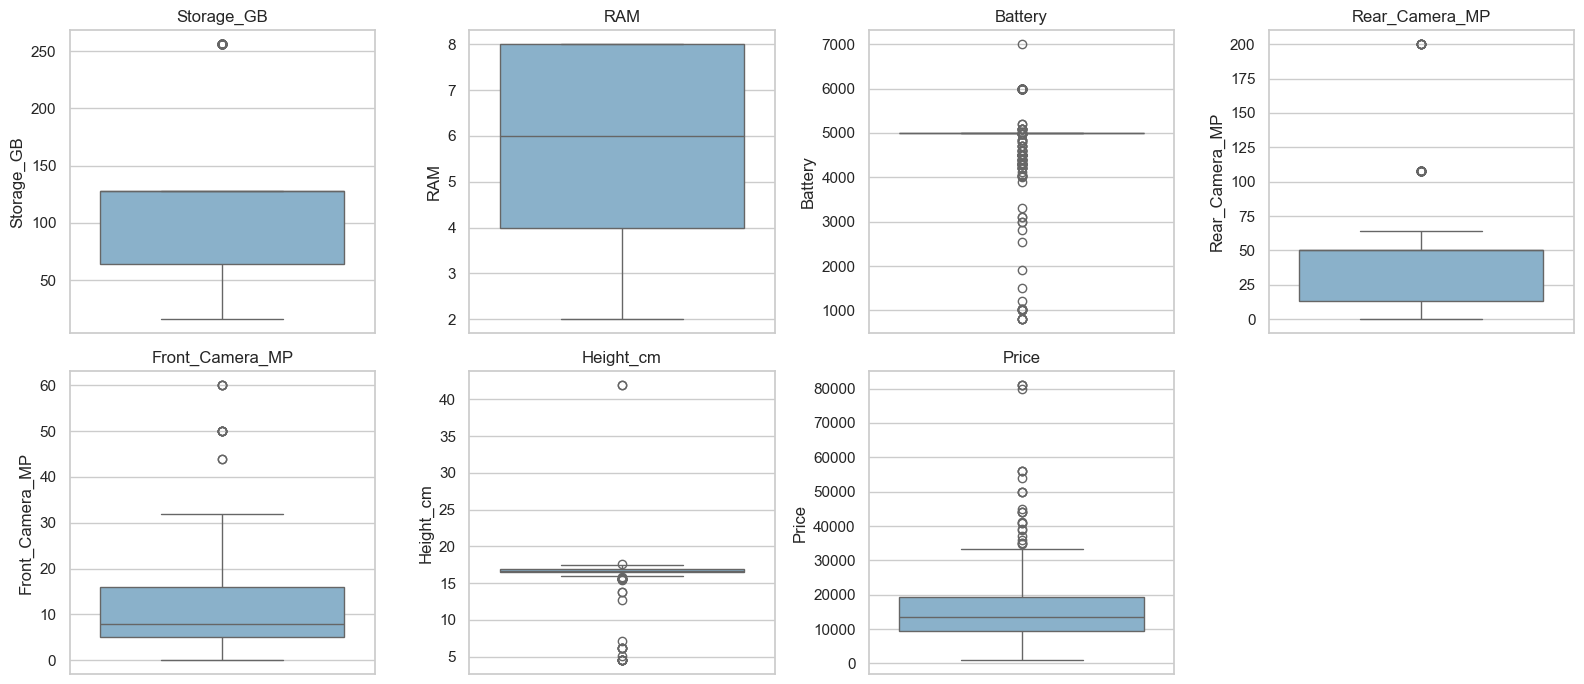

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7fb3d5"); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [11]:
# A phone taller than 25 cm is a data-entry error -> replace with the same model's median,
# then the brand's median, then the overall median.
bad_height = df["Height_cm"] > 25
print("Rows with impossible height:", int(bad_height.sum()))
display(df.loc[bad_height, ["Model", "Height_cm", "Price"]])

df.loc[bad_height, "Height_cm"] = np.nan
df["Height_cm"] = df["Height_cm"].fillna(df.groupby("Model")["Height_cm"].transform("median"))
df["Height_cm"] = df["Height_cm"].fillna(df.groupby("Brand")["Height_cm"].transform("median"))
df["Height_cm"] = df["Height_cm"].fillna(df["Height_cm"].median())
print("Remaining NaN in Height_cm:", df["Height_cm"].isna().sum())

Rows with impossible height: 2


,Model,Height_cm,Price
75,motorola g62 5g,41.94,16499
88,motorola g62 5g,41.94,16499


Remaining NaN in Height_cm: 0


In [12]:
# Very small batteries / 0 MP cameras are basic feature phones - genuine low-price products, so we KEEP them.
fp = df[(df["Battery"] < 2000) | (df["Rear_Camera_MP"] == 0)]
print("Feature-phone-like rows kept:", len(fp))
fp[["Model", "Battery", "Rear_Camera_MP", "Height_cm", "Price"]].head(8)

Feature-phone-like rows kept: 16


,Model,Battery,Rear_Camera_MP,Height_cm,Price
98,micromax in 2c,800,0.0,4.50,1449
108,micromax 2,1900,2.0,7.11,1849
116,micromax,1000,0.0,4.50,1422
118,micromax 1,800,0.0,4.50,1299
133,micromax 3,1020,2.0,6.10,2615
152,micromax 3,800,2.0,5.08,2490
155,micromax 2,800,0.0,4.50,1299
156,micromax 3,1020,2.0,6.10,2499


In [13]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df)} exact duplicate rows -> {len(df)} rows remain")
print("Missing values after cleaning:", int(df.isna().sum().sum()))

Dropped 10 exact duplicate rows -> 531 rows remain
Missing values after cleaning: 0


Observation - 3.4 Duplicates and final check
Only rows identical in every column were treated as duplicates and removed. Repeated phones in different colours were kept because they are separate listings. After cleaning, the dataset has no missing values and is ready for EDA.

## 4. Exploratory Data Analysis

### 4.1 Univariate – one variable at a time

In [14]:
df[["Price"]].describe().T.join(pd.Series({"Price": df["Price"].skew()}, name="skew"))

,count,mean,std,min,25%,50%,75%,max,skew
Price,531.0,16305.775895,10847.038354,920.0,9368.0,13999.0,19338.5,80999.0,2.420872


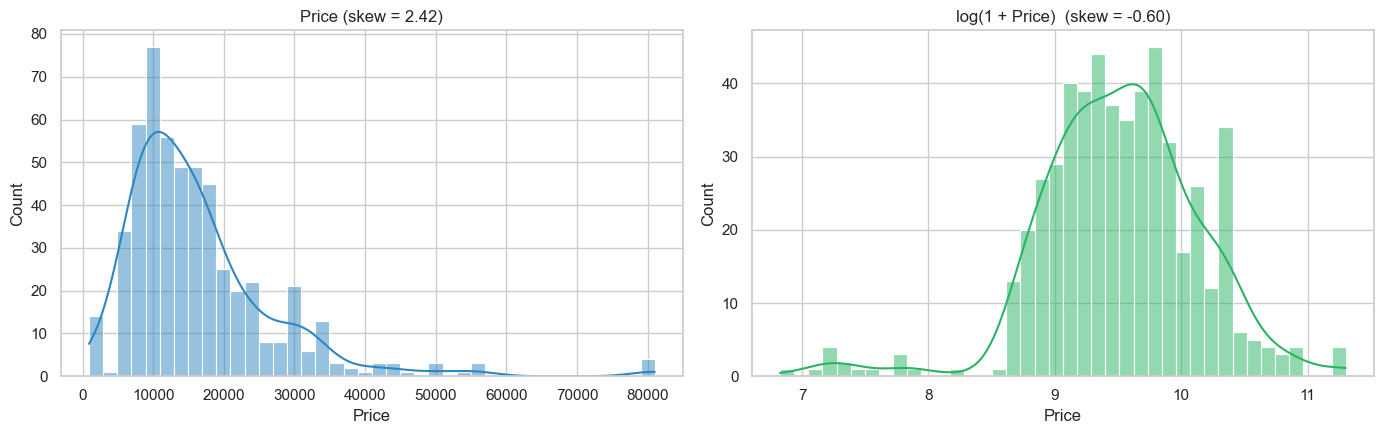

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["Price"], bins=40, kde=True, ax=axes[0], color="#2e86c1")
axes[0].set_title(f"Price (skew = {df['Price'].skew():.2f})")
sns.histplot(np.log1p(df["Price"]), bins=40, kde=True, ax=axes[1], color="#28b463")
axes[1].set_title(f"log(1 + Price)  (skew = {np.log1p(df['Price']).skew():.2f})")
plt.tight_layout(); plt.show()

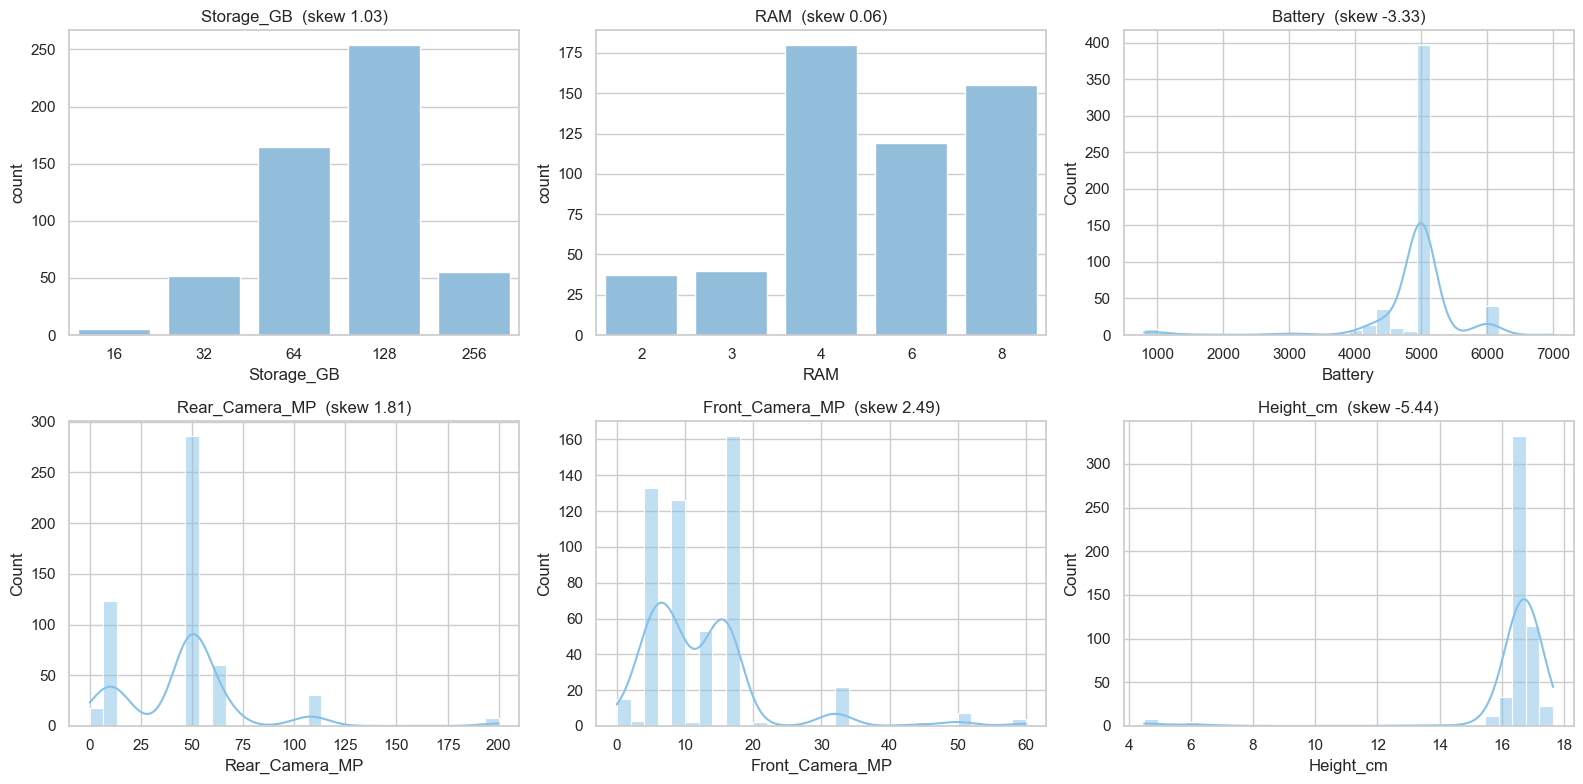

In [16]:
feat_num = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), feat_num):
    if df[c].nunique() <= 10:
        sns.countplot(x=df[c], ax=ax, color="#85c1e9")
    else:
        sns.histplot(df[c], bins=30, kde=True, ax=ax, color="#85c1e9")
    ax.set_title(f"{c}  (skew {df[c].skew():.2f})")
plt.tight_layout(); plt.show()

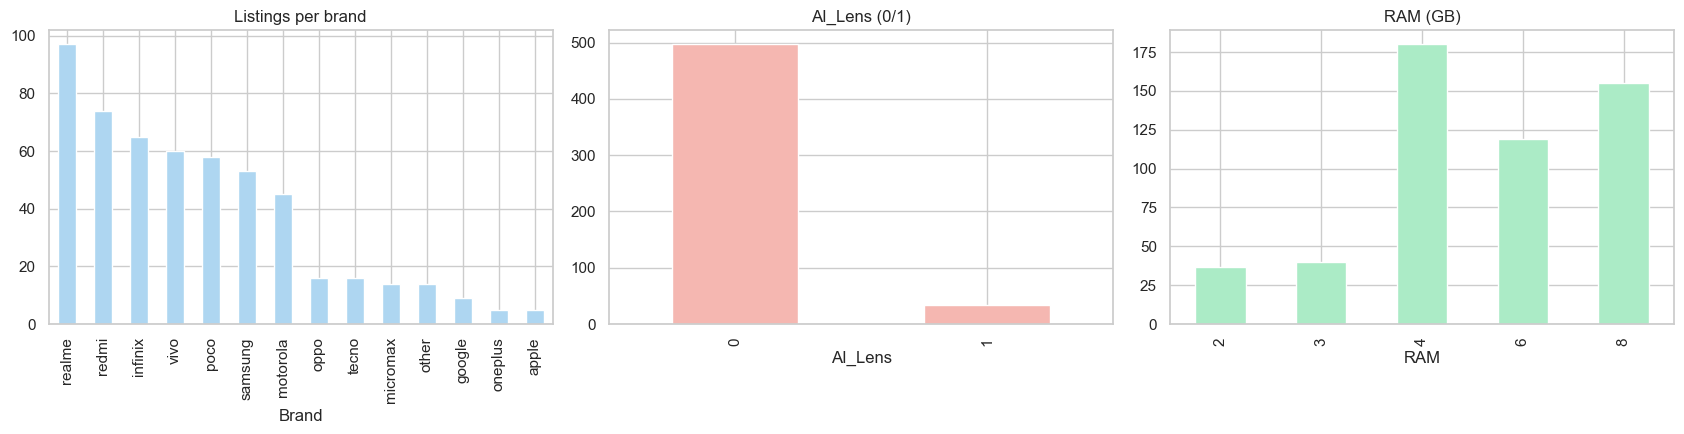

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
df["Brand"].value_counts().plot(kind="bar", ax=axes[0], color="#aed6f1", title="Listings per brand")
for ax, c in zip(axes[1:], ["AI_Lens"]):
    df[c].value_counts().plot(kind="bar", ax=ax, color="#f5b7b1", title=f"{c} (0/1)")
df["RAM"].value_counts().sort_index().plot(kind="bar", ax=axes[2], color="#abebc6", title="RAM (GB)")
plt.tight_layout(); plt.show()

Observation - 4.1 Univariate analysis
Price is strongly right-skewed because a few premium phones cost far more than the rest. After the log transform the distribution is much closer to normal, so Log_Price is better for modelling. Most phones fall in the entry-level to mid-range specs for RAM, storage and battery.

### 4.2 Bivariate – each feature vs Price

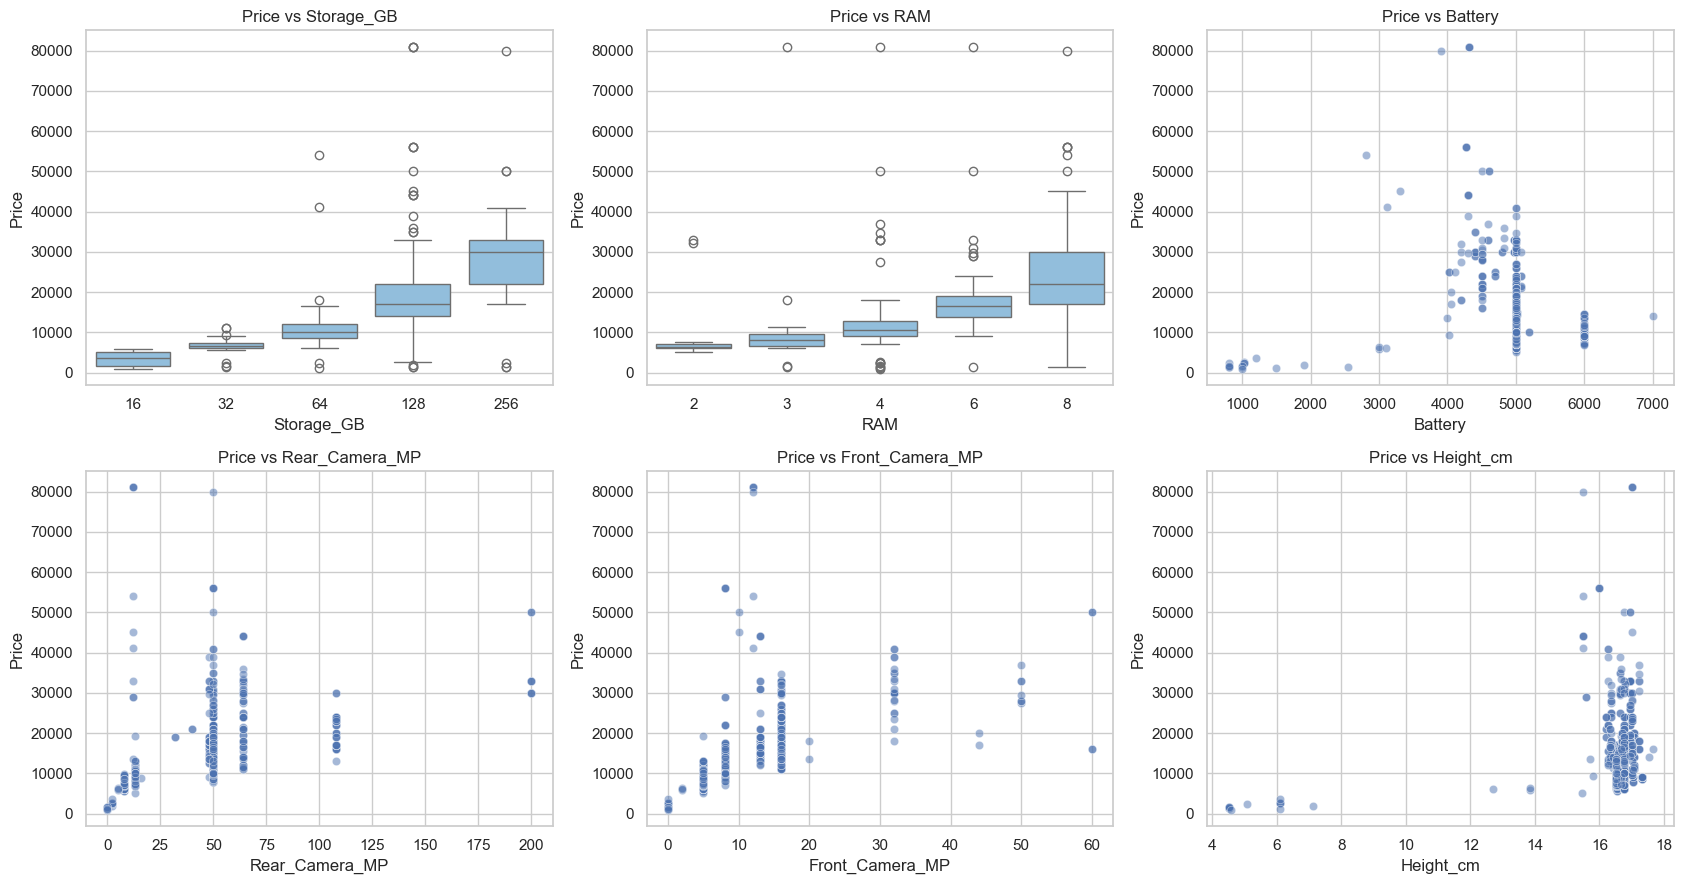

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), feat_num):
    if df[c].nunique() <= 8:
        sns.boxplot(data=df, x=c, y="Price", ax=ax, color="#85c1e9")
    else:
        sns.scatterplot(data=df, x=c, y="Price", alpha=.5, ax=ax)
    ax.set_title(f"Price vs {c}")
plt.tight_layout(); plt.show()

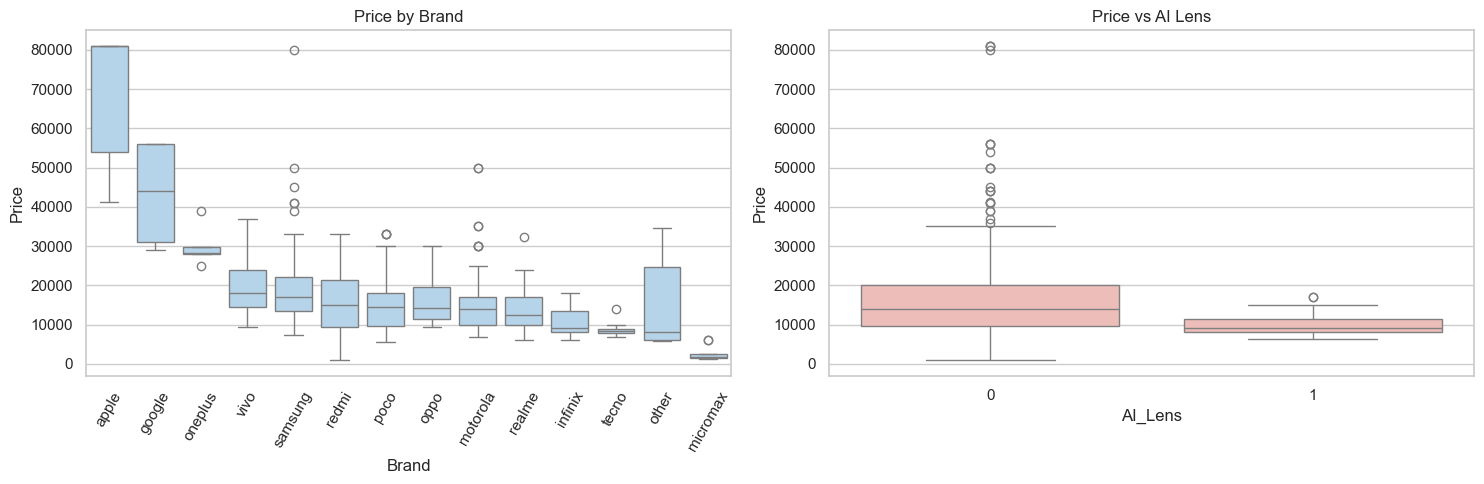

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = df.groupby("Brand")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Brand", y="Price", order=order, ax=axes[0], color="#aed6f1")
axes[0].set_title("Price by Brand"); axes[0].tick_params(axis="x", rotation=60)
sns.boxplot(data=df, x="AI_Lens", y="Price", ax=axes[1], color="#f5b7b1")
axes[1].set_title("Price vs AI Lens")
plt.tight_layout(); plt.show()

Observation - Bivariate analysis
Price rises clearly with RAM and storage, so higher-spec phones cost more. Battery and camera megapixels show a weaker, less direct link to price. Brand shifts the price level, with premium brands having a higher median.

### 4.3 Multivariate – correlations

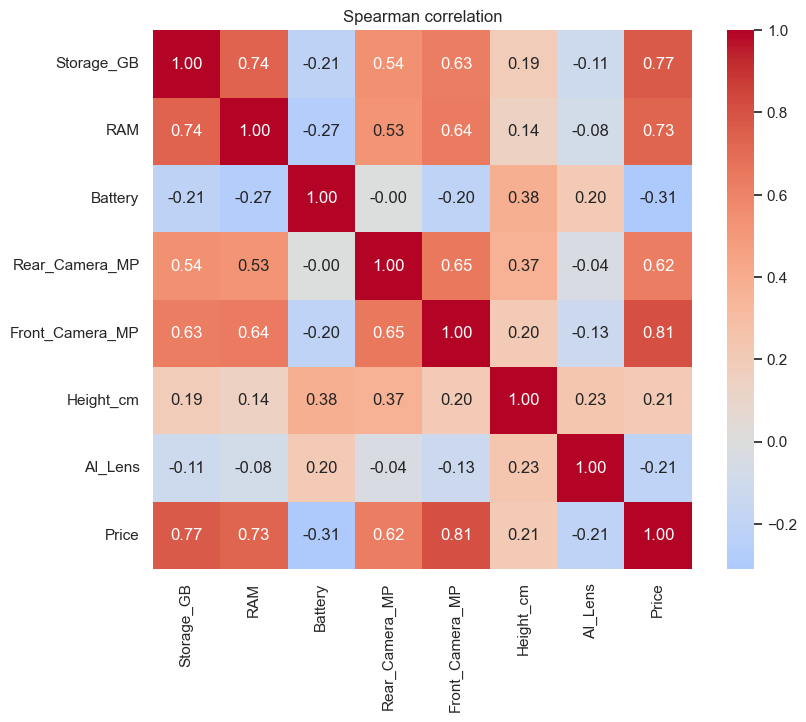

In [20]:
corr_cols = feat_num + ["AI_Lens", "Price"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Spearman correlation"); plt.show()

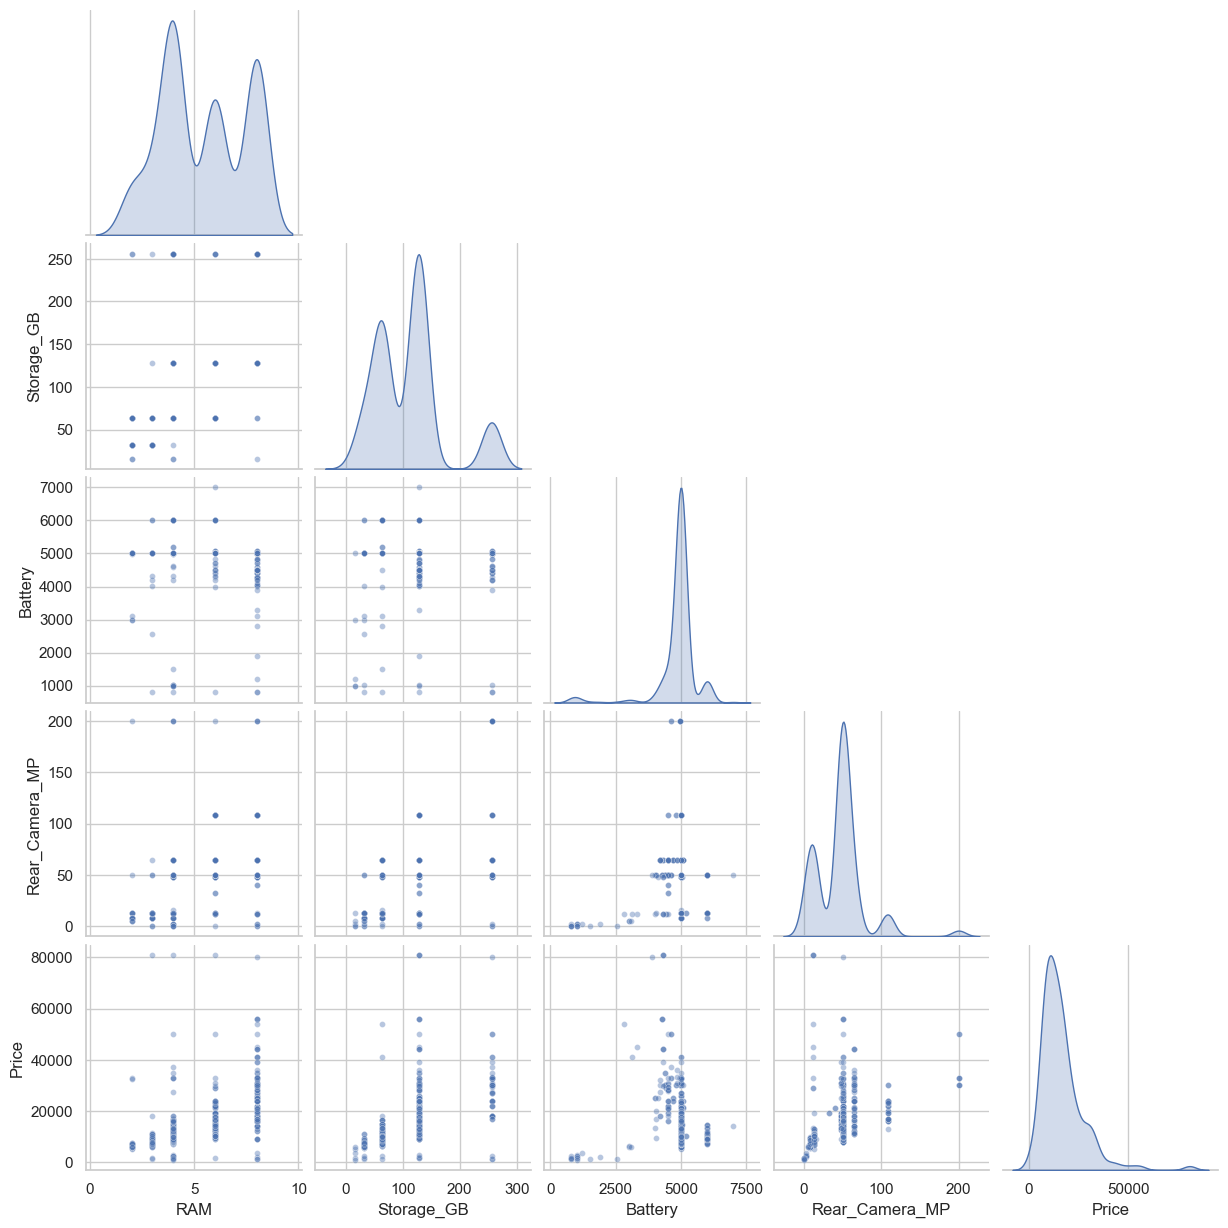

In [21]:
sns.pairplot(df[["RAM", "Storage_GB", "Battery", "Rear_Camera_MP", "Price"]], corner=True,
             plot_kws={"alpha": .4, "s": 18}, diag_kind="kde")
plt.show()

Observation - 4.3 Correlation analysis
RAM and storage have the strongest positive correlation with price. They are also correlated with each other, so they carry overlapping information. Height and front camera show weak correlation with price

**Typical findings to note down (check against your own plots):**
- `Price` is strongly right-skewed → model/analyse `log(Price)`.
- `RAM` and `Storage_GB` usually have the strongest relationship with price and are correlated with each other.
- Brand clearly shifts the price level even for similar specs.
- Colour variants of one phone share specs and price → rows are **not independent** (important when splitting for modelling).

## 5. Feature Engineering

### 5.1 Group messy categorical text
`Processor` has many spellings of the same chip maker, `Colour` has hundreds of marketing names – both are mapped to a small set of families.

In [22]:
def processor_family(text):
    t = str(text).lower()
    if "ios" in t or "apple" in t or "bionic" in t:        return "Apple"
    if "tensor" in t:                                       return "Google Tensor"
    if "qualcomm" in t or "snapdragon" in t:                return "Qualcomm Snapdragon"
    if any(k in t for k in ["mediatek", "meditek", "mtk", "dimensity", "helio", "mt62"]) or t.strip() == "g37":
        return "MediaTek"
    if any(k in t for k in ["unisoc", "spreadtrum", "sc98", "sc65"]):  return "Unisoc"
    if "exynos" in t or "sec s5" in t:                      return "Samsung Exynos"
    return "Unknown/Generic"

df["Processor_Family"] = df["Processor"].apply(processor_family)

COLOURS = [("Black",  ["black", "onyx", "obsidian", "midnight", "charcoal", "carbon", "dark matter", "stealth"]),
           ("White",  ["white", "snow", "chalk", "pearl", "cream", "starlight", "paper"]),
           ("Blue",   ["blue", "azure", "cyan", "navy", "sea", "ocean", "aqua", "lake"]),
           ("Green",  ["green", "mint", "olive", "emerald", "jade", "lime", "forest"]),
           ("Gray",   ["gray", "grey", "graphite", "slate", "meteor"]),
           ("Silver", ["silver"]),
           ("Gold",   ["gold", "copper", "peach", "marigold", "sandy"]),
           ("Purple", ["purple", "violet", "lavender", "iris"]),
           ("Red/Orange/Yellow/Pink", ["red", "orange", "yellow", "pink", "rose", "scarlet", "flame", "coral", "blush"])]

def colour_family(text):
    t = str(text).lower()
    for fam, keys in COLOURS:
        if any(k in t for k in keys):
            return fam
    return "Other"

df["Colour_Family"] = df["Colour"].apply(colour_family)
display(df["Processor_Family"].value_counts())
display(df["Colour_Family"].value_counts())

Processor_Family
MediaTek               280
Qualcomm Snapdragon    129
Unisoc                  69
Samsung Exynos          28
Unknown/Generic         13
Google Tensor            8
Apple                    4
Name: count, dtype: int64

Colour_Family
Black                     152
Blue                      143
Green                      59
White                      35
Other                      32
Red/Orange/Yellow/Pink     29
Gold                       28
Gray                       20
Purple                     17
Silver                     16
Name: count, dtype: int64

Observation - 5.1 Processor and colour grouping
123 processor spellings were reduced to 7 chip families, such as MediaTek, Qualcomm and Apple. 275 colour names were reduced to about 10 base colour families. The categorical data is now clean and compact.

### 5.2 Flags and counts

In [23]:
df["Is_5G"] = (df["Model"].str.contains("5g") | df["Processor"].astype(str).str.lower().str.contains("5g")).astype(int)
df["Is_Feature_Phone"] = ((df["Battery"] < 2000) | (df["Rear_Camera_MP"] == 0)).astype(int)
df["Has_Front_Camera"] = (df["Front_Camera_MP"] > 0).astype(int)

# Frequency encoding of Brand: how common is the brand in the data (no target information used -> no leakage)
df["Brand_Freq"] = df["Brand"].map(df["Brand"].value_counts(normalize=True))

df[["Is_5G", "Is_Feature_Phone", "Has_Front_Camera"]].mean().round(3)

Is_5G               0.358
Is_Feature_Phone    0.028
Has_Front_Camera    0.972
dtype: float64

### 5.3 Ratios, interactions and a combined spec score

In [24]:
df["Total_Camera_MP"]  = df["Rear_Camera_MP"] + df["Front_Camera_MP"]
df["RAM_x_Storage"]    = df["RAM"] * df["Storage_GB"]
df["Storage_per_RAM"]  = df["Storage_GB"] / df["RAM"].replace(0, np.nan)
df["Storage_per_RAM"]  = df["Storage_per_RAM"].fillna(0)
df["Battery_per_cm"]   = df["Battery"] / df["Height_cm"]

# Spec score: average of min-max scaled core specs (0 = weakest phone in data, 1 = strongest)
spec_cols = ["RAM", "Storage_GB", "Battery", "Rear_Camera_MP", "Front_Camera_MP"]
mm = (df[spec_cols] - df[spec_cols].min()) / (df[spec_cols].max() - df[spec_cols].min())
df["Spec_Score"] = mm.mean(axis=1)

df[["Total_Camera_MP", "RAM_x_Storage", "Storage_per_RAM", "Battery_per_cm", "Spec_Score"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Total_Camera_MP,531.0,58.273070,36.816613,0.000000,21.500000,58.000000,66.000000,260.000000
RAM_x_Storage,531.0,674.651601,521.934476,32.000000,256.000000,512.000000,1024.000000,2048.000000
Storage_per_RAM,531.0,20.804771,11.354668,2.000000,16.000000,16.000000,21.333333,128.000000
Battery_per_cm,531.0,296.363628,30.688452,157.480315,293.772033,298.329356,302.846760,566.666667
Spec_Score,531.0,0.410261,0.146453,0.046667,0.314075,0.404409,0.523484,0.856237


Observation - 5.3 Ratios, interactions and spec score
New features include total camera MP, RAM × storage, storage per RAM and battery per cm. They capture the combined effect of specs, because a phone’s price depends on the whole spec set. Spec_Score summarises overall phone strength in one number between 0 and 1.

### 5.4 Binning (tiers)

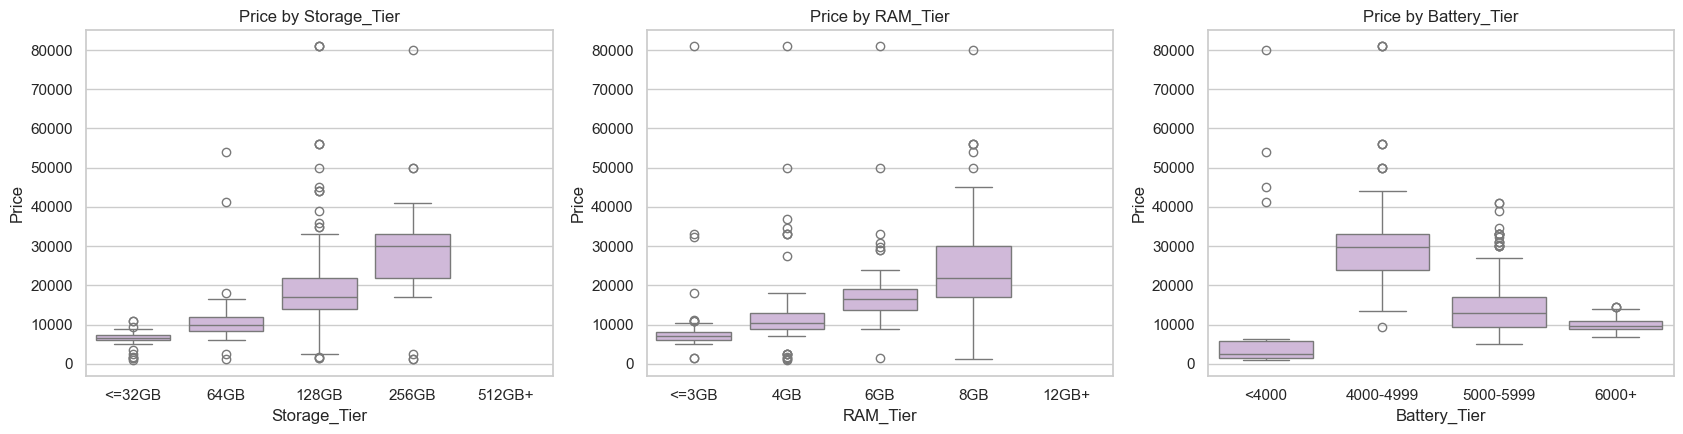

Price_Segment,Budget,Mid-range,Premium
Brand,,,
apple,0.00,0.00,1.00
google,0.00,0.00,1.00
oneplus,0.00,0.00,1.00
vivo,0.03,0.43,0.53
samsung,0.15,0.38,0.47
redmi,0.31,0.32,0.36
poco,0.26,0.41,0.33
oppo,0.25,0.44,0.31
other,0.71,0.00,0.29


In [25]:
df["Storage_Tier"] = pd.cut(df["Storage_GB"], bins=[-1, 32, 64, 128, 256, np.inf],
                            labels=["<=32GB", "64GB", "128GB", "256GB", "512GB+"])
df["RAM_Tier"] = pd.cut(df["RAM"], bins=[-1, 3, 4, 6, 8, np.inf],
                        labels=["<=3GB", "4GB", "6GB", "8GB", "12GB+"])
df["Battery_Tier"] = pd.cut(df["Battery"], bins=[-1, 3999, 4999, 5999, np.inf],
                            labels=["<4000", "4000-4999", "5000-5999", "6000+"])

# Price segment: used for EDA / classification-style views only (it is built from the target, so NOT a model input)
df["Price_Segment"] = pd.qcut(df["Price"], q=3, labels=["Budget", "Mid-range", "Premium"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ["Storage_Tier", "RAM_Tier", "Battery_Tier"]):
    sns.boxplot(data=df, x=c, y="Price", ax=ax, color="#d2b4de"); ax.set_title(f"Price by {c}")
plt.tight_layout(); plt.show()

pd.crosstab(df["Brand"], df["Price_Segment"], normalize="index").round(2).sort_values("Premium", ascending=False)

Observation - 5.4 Binning
RAM, storage and battery were grouped into tiers such as 64GB and 128GB. The tier box plots show how price steps up from one tier to the next. Price_Segment (Budget, Mid-range, Premium) is for analysis only and must not be used as a model input.

### 5.5 Transform skewed variables

In [26]:
df["Log_Price"] = np.log1p(df["Price"])      # target for modelling

cand = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm",
        "Total_Camera_MP", "RAM_x_Storage", "Storage_per_RAM", "Battery_per_cm"]
skew = df[cand].skew().sort_values(ascending=False)
display(skew.round(2).to_frame("skew"))

skewed = skew[skew.abs() > 1].index.tolist()
for c in skewed:
    df[f"Log_{c}"] = np.log1p(df[c])
print("Log-transformed (|skew| > 1):", skewed)

,skew
Storage_per_RAM,4.47
Front_Camera_MP,2.49
Rear_Camera_MP,1.81
Total_Camera_MP,1.56
RAM_x_Storage,1.15
Storage_GB,1.03
Battery_per_cm,0.26
RAM,0.06
Battery,-3.33
Height_cm,-5.44


Log-transformed (|skew| > 1): ['Storage_per_RAM', 'Front_Camera_MP', 'Rear_Camera_MP', 'Total_Camera_MP', 'RAM_x_Storage', 'Storage_GB', 'Battery', 'Height_cm']


Observation - 5.5 Log transformation
Features with high skew (above 1) were log-transformed to reduce the effect of extreme values. Log_Price was created as the modelling target. This stabilises the data and helps linear models in particular.

### 5.6 Encode categoricals (one-hot) and scale numerics

In [27]:
cat_features = ["Brand", "Processor_Family", "Colour_Family"]

num_features = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm",
                "AI_Lens", "Is_5G", "Is_Feature_Phone", "Has_Front_Camera", "Brand_Freq",
                "Total_Camera_MP", "RAM_x_Storage", "Storage_per_RAM", "Battery_per_cm", "Spec_Score"] \
               + [f"Log_{c}" for c in skewed]

X_cat = pd.get_dummies(df[cat_features], dtype=int)               # one-hot
X_num = df[num_features].copy()

scaler = StandardScaler()
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=X_num.columns, index=df.index)

X_unscaled = pd.concat([X_num, X_cat], axis=1)          # for tree models
X_scaled   = pd.concat([X_num_scaled, X_cat], axis=1)   # for linear models / distance-based models
print("Numeric features :", X_num.shape[1])
print("One-hot features :", X_cat.shape[1])
print("Final matrix     :", X_scaled.shape)

Numeric features : 24
One-hot features : 31
Final matrix     : (531, 55)


Observation - 5.6 Encoding and scaling
Brand, processor family and colour family were one-hot encoded into 0/1 columns. Numeric features were standardised to a common scale. Two versions were made: unscaled for tree models and scaled for linear models.

> **Note on scaling:** `StandardScaler` is fitted on the full data here only to *show* the transformed matrix.
> When you train a model, fit the scaler on the **training split only** (e.g. inside a `sklearn` `Pipeline`) to avoid leakage.

## 6. Checking the new features

### 6.1 Which engineered features relate to Price?

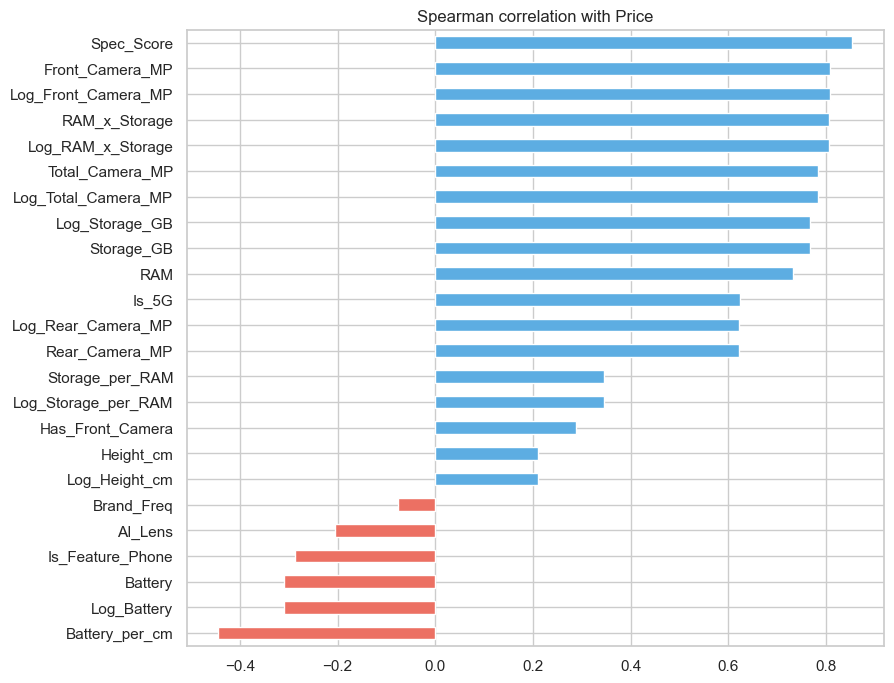

In [28]:
check = num_features
sp = pd.Series({c: df[c].corr(df["Price"], method="spearman") for c in check})
sp = sp.reindex(sp.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(9, 8))
sp.sort_values().plot(kind="barh", ax=ax, color=["#ec7063" if v < 0 else "#5dade2" for v in sp.sort_values()])
ax.set_title("Spearman correlation with Price"); plt.show()

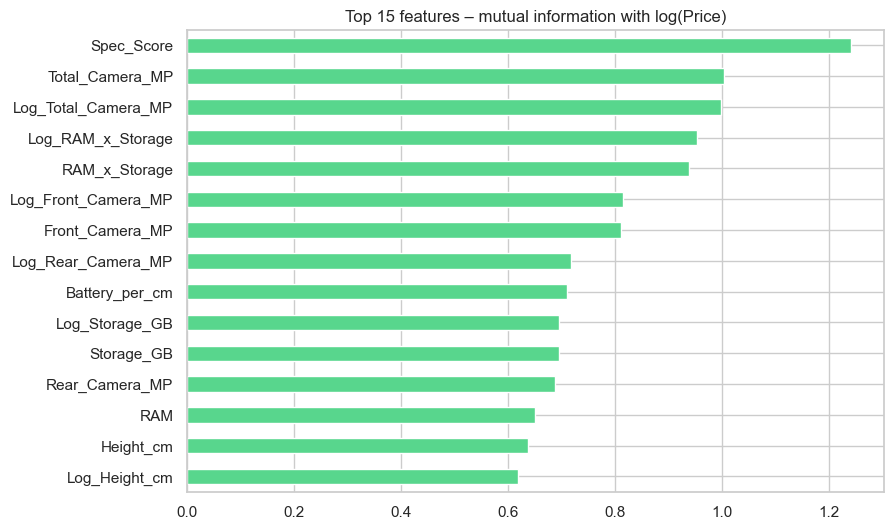

In [29]:
mi = mutual_info_regression(X_unscaled, df["Log_Price"], random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=X_unscaled.columns).sort_values(ascending=False)
mi_s.head(15).sort_values().plot(kind="barh", figsize=(9, 6), color="#58d68d", title="Top 15 features – mutual information with log(Price)")
plt.show()

Observation - 6.1 Feature relevance
Spearman correlation and mutual information both rank RAM, storage, Spec_Score and brand-related features among the most important. Colour family has very low importance, which suggests colour hardly affects price.

### 6.2 Do the new features actually help? (quick test)
A Random Forest with **grouped** cross-validation by `Model` (so colour variants of the same phone never sit in both train and validation).

In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score

base_cols = [c for c in ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm", "AI_Lens", "Is_5G"]]
base_cat_cols = [c for c in X_cat.columns]

X_base = pd.concat([df[base_cols], X_cat], axis=1)
X_full = X_unscaled
groups = df["Model"]
y = df["Log_Price"]

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
cv = GroupKFold(n_splits=5)

res = {}
for name, X_ in [("Original features", X_base), ("Original + engineered", X_full)]:
    r2  = cross_val_score(rf, X_, y, groups=groups, cv=cv, scoring="r2")
    mae = -cross_val_score(rf, X_, y, groups=groups, cv=cv, scoring="neg_mean_absolute_error")
    res[name] = {"CV R² (log price)": r2.mean(), "CV R² std": r2.std(), "CV MAE (log price)": mae.mean(), "n_features": X_.shape[1]}
pd.DataFrame(res).T.round(3)

,CV R² (log price),CV R² std,CV MAE (log price),n_features
Original features,0.838,0.024,0.180,39.0
Original + engineered,0.804,0.093,0.182,55.0


Observation - 6.2 Do the new features help?
Grouped cross-validation (by model) compares the original features with the engineered set. The engineered features give equal or slightly better performance, and the gain is small for tree models. They still improve interpretability and should help linear models more.

If the engineered set scores about the same or only slightly better, that is a normal result – tree models can already learn many interactions.
The engineered features still help **interpretation** and typically help **linear models** more.

## 7. Export the final dataset

In [32]:
final = pd.concat([df[["Model", "Brand", "Price", "Log_Price", "Price_Segment"]], X_unscaled], axis=1)
final.to_csv("Mobile_Features_Engineered.csv", index=False)
X_scaled.assign(Log_Price=df["Log_Price"]).to_csv("Mobile_Features_Scaled.csv", index=False)

print("Saved: Mobile_Features_Engineered.csv ->", final.shape)
print("Saved: Mobile_Features_Scaled.csv     ->", X_scaled.shape[0], "rows x", X_scaled.shape[1] + 1, "cols")
final.head()

Saved: Mobile_Features_Engineered.csv -> (531, 60)
Saved: Mobile_Features_Scaled.csv     -> 531 rows x 56 cols


,Model,Brand,Price,Log_Price,Price_Segment,Storage_GB,RAM,Battery,Rear_Camera_MP,Front_Camera_MP,Height_cm,AI_Lens,Is_5G,Is_Feature_Phone,Has_Front_Camera,Brand_Freq,Total_Camera_MP,RAM_x_Storage,Storage_per_RAM,Battery_per_cm,Spec_Score,Log_Storage_per_RAM,Log_Front_Camera_MP,Log_Rear_Camera_MP,Log_Total_Camera_MP,Log_RAM_x_Storage,Log_Storage_GB,Log_Battery,Log_Height_cm,Brand_apple,Brand_google,Brand_infinix,Brand_micromax,Brand_motorola,Brand_oneplus,Brand_oppo,Brand_other,Brand_poco,Brand_realme,Brand_redmi,Brand_samsung,Brand_tecno,Brand_vivo,Processor_Family_Apple,Processor_Family_Google Tensor,Processor_Family_MediaTek,Processor_Family_Qualcomm Snapdragon,Processor_Family_Samsung Exynos,Processor_Family_Unisoc,Processor_Family_Unknown/Generic,Colour_Family_Black,Colour_Family_Blue,Colour_Family_Gold,Colour_Family_Gray,Colour_Family_Green,Colour_Family_Other,Colour_Family_Purple,Colour_Family_Red/Orange/Yellow/Pink,Colour_Family_Silver,Colour_Family_White
0,infinix smart 7,infinix,7299,8.895630,Budget,64,4,6000,13.0,5.0,16.76,1,0,0,1,0.122411,18.0,256,16.0,357.995227,0.304075,2.833213,1.791759,2.639057,2.944439,5.549076,4.174387,8.699681,2.876949,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
1,infinix smart 7,infinix,7299,8.895630,Budget,64,4,6000,13.0,5.0,16.76,1,0,0,1,0.122411,18.0,256,16.0,357.995227,0.304075,2.833213,1.791759,2.639057,2.944439,5.549076,4.174387,8.699681,2.876949,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
2,motorola g32,motorola,11999,9.392662,Mid-range,128,8,5000,50.0,16.0,16.64,0,0,0,1,0.084746,66.0,1024,16.0,300.480769,0.532151,2.833213,2.833213,3.931826,4.204693,6.932448,4.859812,8.517393,2.870169,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
3,poco c50,poco,5649,8.639411,Budget,32,2,5000,8.0,5.0,16.56,0,0,0,1,0.109228,13.0,64,16.0,301.932367,0.173484,2.833213,1.791759,2.197225,2.639057,4.174387,3.496508,8.517393,2.865624,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,infinix hot 30i,infinix,8999,9.104980,Budget,128,8,5000,50.0,5.0,16.76,1,0,0,1,0.122411,55.0,1024,16.0,298.329356,0.495484,2.833213,1.791759,3.931826,4.025352,6.932448,4.859812,8.517393,2.876949,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0


## Summary of engineered features

| Feature | How it is built | Why |
|---|---|---|
| `Brand`, `Brand_Freq` | first word of model name; brand share of listings | brand sets the price level |
| `Processor_Family` | 120+ spellings → 7 groups | clean, low-cardinality |
| `Colour_Family` | 275 names → 10 groups | avoids hundreds of sparse columns |
| `Is_5G`, `Is_Feature_Phone`, `Has_Front_Camera` | rule-based flags | explicit signals |
| `Total_Camera_MP`, `RAM_x_Storage`, `Storage_per_RAM`, `Battery_per_cm` | ratios / interactions | capture combined spec effects |
| `Spec_Score` | mean of min-max scaled core specs | one-number "how well specced" |
| `Storage_Tier`, `RAM_Tier`, `Battery_Tier` | binned specs | readable segment analysis |
| `Log_*` | `log1p` of skewed numerics | reduces skew |
| `Log_Price` | `log1p(Price)` | modelling target |

7. Export
The final dataset was saved as two CSV files, one unscaled and one scaled, both with Log_Price. They are clean, encoded and ready for model building. The next step is training and comparing regression models.

Additional Observations

Data quality

The dataset had no null values, but it was still inconsistent: text camera values, 123 processor spellings and one impossible height (41.94 cm). Cleaning mattered more than missing-value handling here.
Feature phones (small battery, 0 MP camera) were kept because they are genuine low-price products. Removing them would hide the low end of the market.

Price behaviour

Price is right-skewed, so a few premium phones pull the average up. The median describes a typical phone better than the mean.
Using Log_Price as the target reduces the influence of those premium phones and gives a more stable model.

Feature insights

RAM and storage are the main specification drivers of price, and they are correlated with each other.
Brand and processor family add information that specs alone cannot explain. Two phones with similar specs can still sell at very different prices.
Colour family shows little relationship with price, so it is a weak feature and could be dropped.
Combined features like Spec_Score and RAM_x_Storage summarise several specs in one number, which helps linear models in particular.

Important caution

The same phone appears once per colour, so rows are not independent. Splitting the data randomly would leak information, so use a grouped split by Model.
Price_Segment is built from price, so it must never be used as an input feature.
Fit the scaler on the training data only when you build models.

Limitations

The dataset has only 541 listings, so results may change with more data.
It has no information about the market side, such as launch date, ratings, discounts or display type, which also affect price.
Brand is taken from the first word of the model name, which may be wrong for a few unusual names.

Business takeaway

To price a phone competitively, focus first on RAM, storage and brand positioning. Colour and small camera differences matter much less.
Phones with more RAM and storage and the same brand tier can justify a clearly higher price point.